In [151]:
#analysis -- feature eng -- model -- web app (Streamlit)

In [152]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [153]:
# Définir certains paramètres d'affichage 
pd.set_option("display.max_columns", None)

In [154]:
sns.set_style("whitegrid")

In [155]:
# 1. Chargement du dataset 
df = pd.read_csv("german_credit_data.csv")

In [156]:
# 2. Affichage des 5 premières lignes
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [157]:
# 3. Taille de notre jeu de données 
df.shape

(1000, 11)

In [158]:
# 4. Voir les infos 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
 10  Risk              1000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 86.1 KB


In [159]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,NaN,NaN,NaN,499.5,288.819436,0.0,249.75,499.5,749.25,999.0
Age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.653614,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Saving accounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking account,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2. Analyse Univariée

In [160]:
df.columns

Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

In [161]:
# 5. Renommage des colonnes
df = df.rename(columns={
    "Age": "age",
    "Sex": "sexe",
    "Job": "qualification_emploi",
    "Housing": "logement",
    "Saving accounts": "compte_epargne",
    "Checking account": "compte_courant",
    "Credit amount": "montant_credit",
    "Duration": "duree",
    "Purpose": "objet_credit",
    "Risk": "risque",
})

In [162]:
# Dictionnaires de traduction
map_sexe = {"male": "Homme", "female": "Femme"}

# map_emploi = {
#    0: "Non qualifié, non résident",
#    1: "Non qualifié, résident",
#    2: "Qualifié",
#    3: "Très qualifié / cadre",
#}

map_logement = {"own": "Propriétaire", "rent": "Locataire", "free": "Logé gratuitement"}

map_epargne = {
    "little": "Faible",
    "moderate": "Modérée",
    "quite rich": "Assez élevée",
    "rich": "Élevée",
}

map_courant = {
    "little": "Faible",
    "moderate": "Modéré",
    "rich": "Élevé",
}

map_objet = {
    "car": "Automobile",
    "furniture/equipment": "Meubles / équipement",
    "radio/TV": "Radio / TV",
    "domestic appliances": "Électroménager",
    "repairs": "Réparations",
    "education": "Éducation",
    "business": "Création / activité professionnelle",
    "vacation/others": "Vacances / autres",
}

map_risque = {"good": "Bon", "bad": "Mauvais"}

# 6. Application
df["sexe"] = df["sexe"].map(map_sexe)
# df["qualification_emploi"] = df["qualification_emploi"].map(map_emploi)
df["logement"] = df["logement"].map(map_logement)
df["compte_epargne"] = df["compte_epargne"].map(map_epargne)
df["compte_courant"] = df["compte_courant"].map(map_courant)
df["objet_credit"] = df["objet_credit"].map(map_objet)
df["risque"] = df["risque"].map(map_risque)

In [163]:
df.columns

Index(['Unnamed: 0', 'age', 'sexe', 'qualification_emploi', 'logement',
       'compte_epargne', 'compte_courant', 'montant_credit', 'duree',
       'objet_credit', 'risque'],
      dtype='str')

In [164]:
# 7. Suppression de l'index 
df = df.drop(columns = "Unnamed: 0")

In [165]:
# 8. Vérification des valeurs manquantes
print(df.isna().sum())

age                       0
sexe                      0
qualification_emploi      0
logement                  0
compte_epargne          183
compte_courant          394
montant_credit            0
duree                     0
objet_credit              0
risque                    0
dtype: int64


In [166]:
# 9. Vérification des doublons 
df.duplicated().sum()

np.int64(0)

In [167]:
# 10. Traitement des valeurs manquantes 
df = df.dropna().reset_index(drop=True)
df

,age,sexe,qualification_emploi,logement,compte_epargne,compte_courant,montant_credit,duree,objet_credit,risque
0,22,Femme,2,Propriétaire,Faible,Modéré,5951,48,Radio / TV,Mauvais
1,45,Homme,2,Logé gratuitement,Faible,Faible,7882,42,Meubles / équipement,Bon
2,53,Homme,2,Logé gratuitement,Faible,Faible,4870,24,Automobile,Mauvais
3,35,Homme,3,Locataire,Faible,Modéré,6948,36,Automobile,Bon
4,28,Homme,3,Propriétaire,Faible,Modéré,5234,30,Automobile,Mauvais
...,...,...,...,...,...,...,...,...,...,...
517,48,Homme,1,Propriétaire,Faible,Modéré,1743,24,Radio / TV,Bon
518,30,Homme,3,Propriétaire,Faible,Faible,3959,36,Meubles / équipement,Bon
519,40,Homme,3,Propriétaire,Faible,Faible,3857,30,Automobile,Bon
520,23,Homme,2,Logé gratuitement,Faible,Faible,1845,45,Radio / TV,Mauvais


In [168]:
print(df[["compte_epargne", "compte_courant"]].isna().sum())  
print('-------------')
print(df["compte_epargne"].value_counts())
print('-------------')
print(df["compte_courant"].value_counts())

compte_epargne    0
compte_courant    0
dtype: int64
-------------
compte_epargne
Faible          412
Modérée          64
Assez élevée     23
Élevée           23
Name: count, dtype: int64
-------------
compte_courant
Faible    245
Modéré    224
Élevé      53
Name: count, dtype: int64


In [169]:
df.columns

Index(['age', 'sexe', 'qualification_emploi', 'logement', 'compte_epargne',
       'compte_courant', 'montant_credit', 'duree', 'objet_credit', 'risque'],
      dtype='str')

In [170]:
# Conversion montant du crédit (Du Deutsche Mark, monnaie allemande 1994) en franc CFA en passant par l'Euro 

TAUX_DM_FCFA = 655.957 / 1.95583   # ≈ 335.39

# On conserve l'original pour la traçabilité
df["montant_credit_dm"] = df["montant_credit"]
df["montant_credit"] = (df["montant_credit_dm"] * TAUX_DM_FCFA).round(0).astype(int)

print(df[["montant_credit_dm", "montant_credit"]].describe().round(0))

       montant_credit_dm  montant_credit
count              522.0           522.0
mean              3279.0       1099644.0
std               2929.0        982396.0
min                276.0         92566.0
25%               1298.0        435163.0
50%               2326.0        780274.0
75%               3971.0       1331900.0
max              18424.0       6179142.0


#### Variables numériques 

In [171]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,522.0,NaN,NaN,NaN,34.888889,11.787918,19.0,26.0,31.5,41.0,75.0
sexe,522,2,Homme,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qualification_emploi,522.0,NaN,NaN,NaN,1.875479,0.682811,0.0,2.0,2.0,2.0,3.0
logement,522,3,Propriétaire,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
compte_epargne,522,4,Faible,412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
compte_courant,522,3,Faible,245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
montant_credit,522.0,NaN,NaN,NaN,1099643.547893,982396.118486,92566.0,435162.75,780274.5,1331900.0,6179142.0
duree,522.0,NaN,NaN,NaN,21.33908,12.474079,6.0,12.0,18.0,26.75,72.0
objet_credit,522,8,Automobile,173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
risque,522,2,Bon,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN


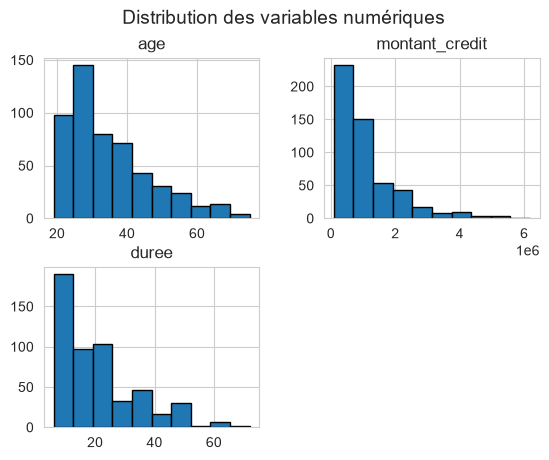

In [172]:
df[["age", "montant_credit", "duree"]].hist(bins=10, edgecolor = "black")
plt.suptitle("Distribution des variables numériques", fontsize = 14)
plt.show()

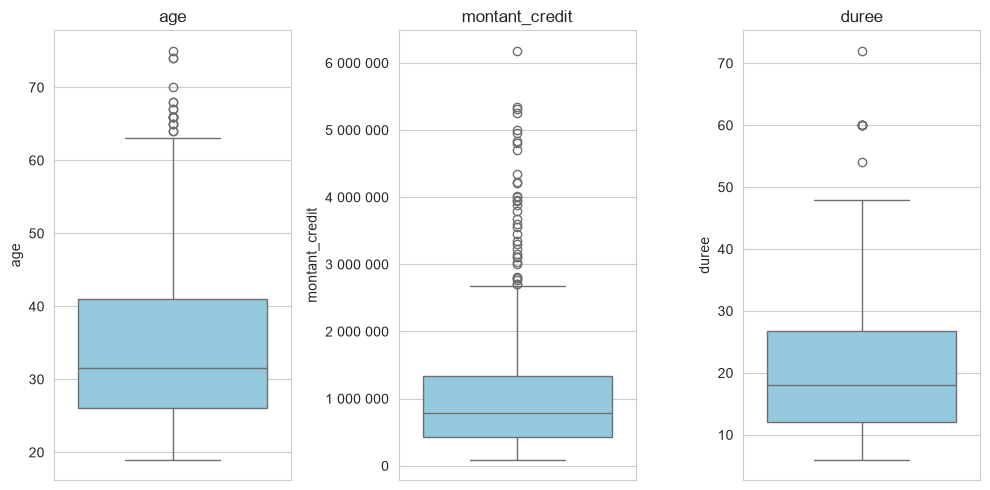

In [173]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(10, 5))
for i, col in enumerate(["age", "montant_credit", "duree"]):
    ax = plt.subplot(1, 3, i + 1)          
    sns.boxplot(y=df[col], color="skyblue", ax=ax)
    ax.set_title(col)
    if col == "montant_credit":
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
        )

plt.tight_layout()
plt.show()

In [174]:
df.query("duree >= 60")

,age,sexe,qualification_emploi,logement,compte_epargne,compte_courant,montant_credit,duree,objet_credit,risque,montant_credit_dm
18,63,Homme,2,Propriétaire,Faible,Faible,2292695,60,Création / activité professionnelle,Mauvais,6836
176,24,Femme,3,Propriétaire,Modérée,Modéré,2484536,60,Automobile,Mauvais,7408
199,60,Femme,3,Logé gratuitement,Modérée,Modéré,4957668,60,Vacances / autres,Mauvais,14782
358,24,Homme,2,Propriétaire,Modérée,Modéré,1876482,72,Radio / TV,Mauvais,5595
378,27,Homme,3,Propriétaire,Faible,Modéré,4704452,60,Automobile,Mauvais,14027
489,42,Homme,2,Logé gratuitement,Faible,Modéré,2108904,60,Éducation,Mauvais,6288
507,36,Homme,2,Locataire,Faible,Faible,2447308,60,Création / activité professionnelle,Mauvais,7297


#### Variables catégorielles

In [175]:
categorical_cols = ["sexe", "qualification_emploi", "logement", "compte_epargne", "compte_courant", "objet_credit"]

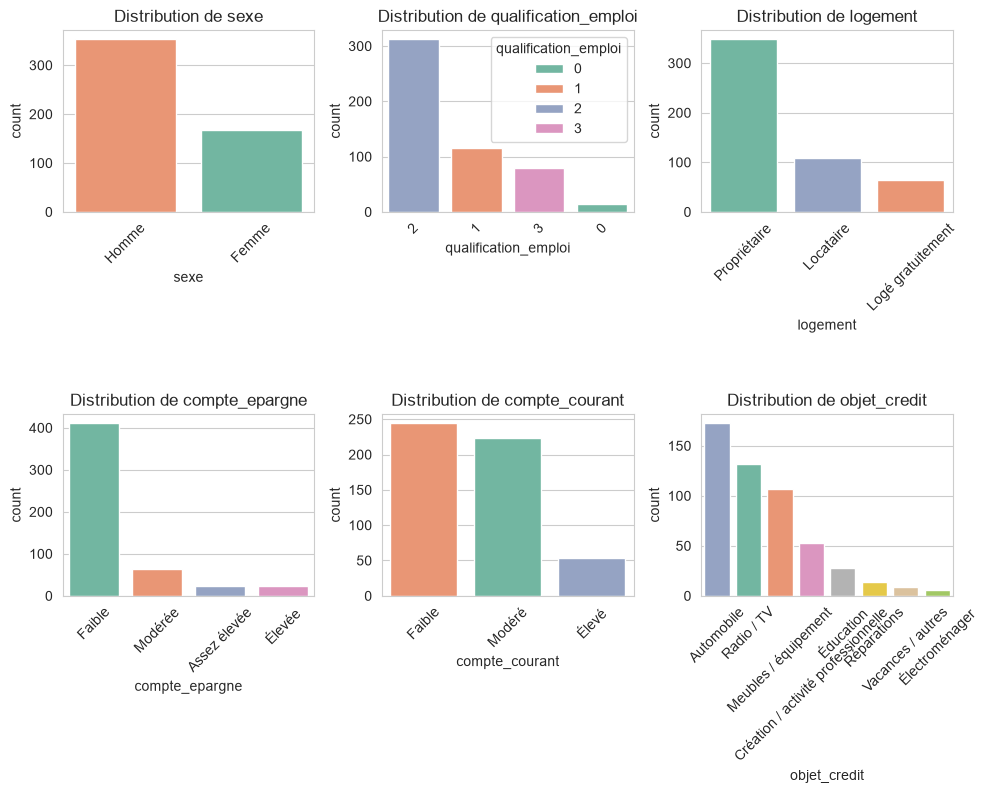

In [176]:
plt.figure(figsize=(10, 10))
for i , col in enumerate(categorical_cols): 
    plt.subplot(3, 3, i + 1) 
    sns.countplot(x = col, data = df, hue=col, palette="Set2", order= df[col].value_counts().index)
    plt.title(f"Distribution de {col}")
    plt.xticks(rotation = 45) 

plt.tight_layout()
plt.show()

In [177]:
# Matrice de corrélation 
corr = df[["age", "qualification_emploi", "montant_credit", 'duree']].corr()

In [178]:
corr

,age,qualification_emploi,montant_credit,duree
age,1.000000,0.039771,0.082014,0.001549
qualification_emploi,0.039771,1.000000,0.334721,0.200794
montant_credit,0.082014,0.334721,1.000000,0.613298
duree,0.001549,0.200794,0.613298,1.000000


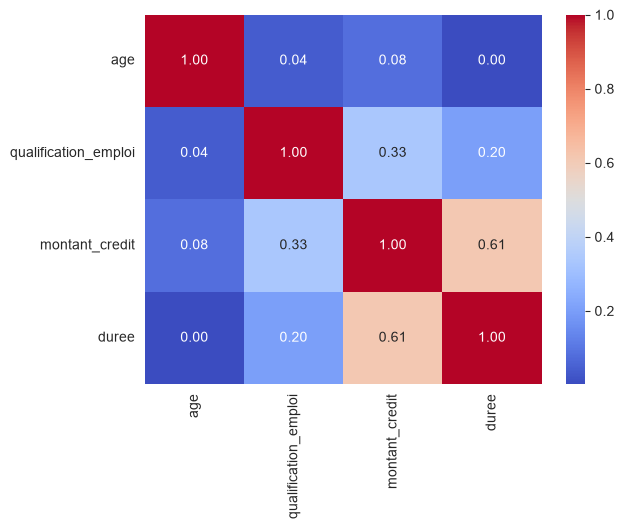

In [179]:
# Afficher visuellement la matrice de correlation avec seaborn 
sns.heatmap(corr, annot=True, cmap= "coolwarm", fmt = ".2f")
plt.show()

On peut remarquer qu'il n'y a pas de fortes corrélations dans notre jeu de données. La valeur la plus élévée qu'on voit est 0.61 entre le montant du crédit et la durée. On peut donc en déduire que si le montant du crédit augmente, la durée augmente aussi.
Les gens  

Donc pour notre dataset, pour les montants de crédits élevés, les gens recherchent une durée plus longue.   

In [180]:
# Montant moyen du crédit par type d'emploi et par sexe 
df.groupby("qualification_emploi")["montant_credit"].mean()

qualification_emploi
0    5.929136e+05
1    7.548573e+05
2    1.049465e+06
3    1.894520e+06
Name: montant_credit, dtype: float64

In [181]:
df.groupby("sexe")["montant_credit"].mean()

sexe
Femme    9.850950e+05
Homme    1.154006e+06
Name: montant_credit, dtype: float64

In [182]:
# Tableau croisé dynamique 
tab = pd.pivot_table(df, values="montant_credit", index="logement", columns = "objet_credit")

(tab.style
    .format(lambda x: f"{x:,.0f}".replace(",", " ")))

objet_credit,Automobile,Création / activité professionnelle,Meubles / équipement,Radio / TV,Réparations,Vacances / autres,Éducation,Électroménager
logement,,,,,,,,
Locataire,1 139 736,2 072 962,969 360,717 054,799 559,nan,881 345,nan
Logé gratuitement,1 737 402,1 577 989,1 482 218,703 303,399 109,2 630 317,1 782 322,nan
Propriétaire,1 046 566,1 249 638,1 016 587,773 940,1 003 976,3 461 793,880 413,447 236


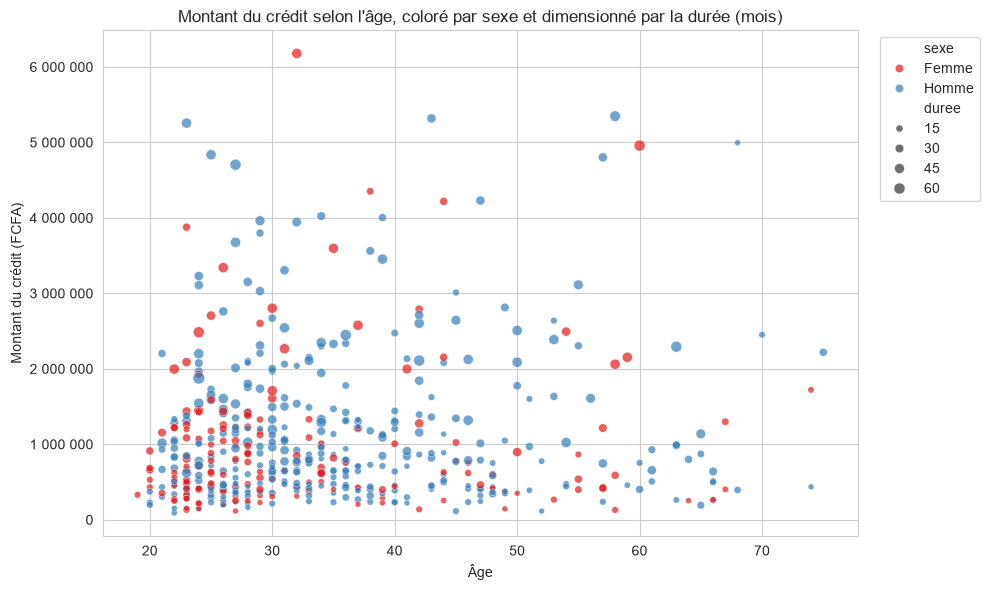

In [183]:
from matplotlib.ticker import FuncFormatter

plt.close("all")                               # repart d'un état propre
fig, ax = plt.subplots(figsize=(10, 6))        # ax est défini ICI, sans ambiguïté

sns.scatterplot(data=df, x="age", y="montant_credit", hue="sexe",
                size="duree", alpha=0.7, palette="Set1", ax=ax)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
ax.set_xlabel("Âge")
ax.set_ylabel("Montant du crédit (FCFA)")
ax.set_title("Montant du crédit selon l'âge, coloré par sexe et dimensionné par la durée (mois)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

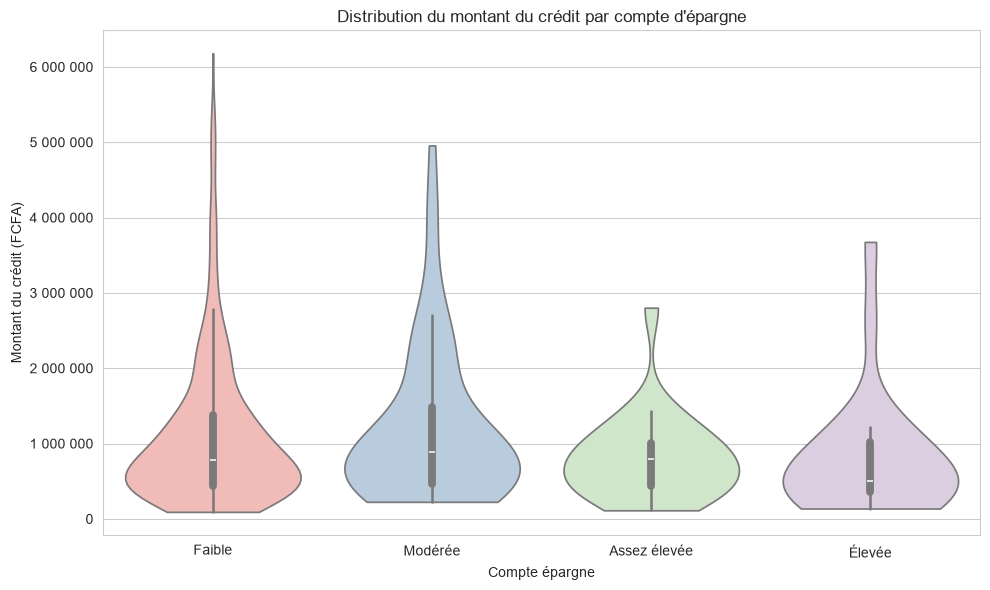

In [184]:
# Diagramme en violon
fig, ax = plt.subplots(figsize=(10, 6))  
sns.violinplot(data= df, x= "compte_epargne", y = "montant_credit", hue="compte_epargne", palette = "Pastel1", legend=False, cut=0, ax=ax)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
ax.set_xlabel("Compte épargne")
ax.set_ylabel("Montant du crédit (FCFA)")
ax.set_title("Distribution du montant du crédit par compte d'épargne")


plt.tight_layout()
plt.show()

In [185]:
(df.groupby("compte_epargne")["montant_credit"]
   .agg(effectif="count", mediane="median", q1=lambda s: s.quantile(.25),
        q3=lambda s: s.quantile(.75), maximum="max")
   .loc[["Faible", "Modérée", "Assez élevée", "Élevée"]]
   .round(0))

,effectif,mediane,q1,q3,maximum
compte_epargne,,,,,
Faible,412,778430.0,438097.0,1382040.0,6179142
Modérée,64,882399.0,457298.0,1485422.0,4957668
Assez élevée,23,791510.0,437678.0,1013032.0,2803152
Élevée,23,507103.0,359366.0,1023261.0,3676160


In [186]:
# Analyse du risque (cible)
df['risque'].value_counts(normalize=True) * 100

risque
Bon        55.747126
Mauvais    44.252874
Name: proportion, dtype: float64

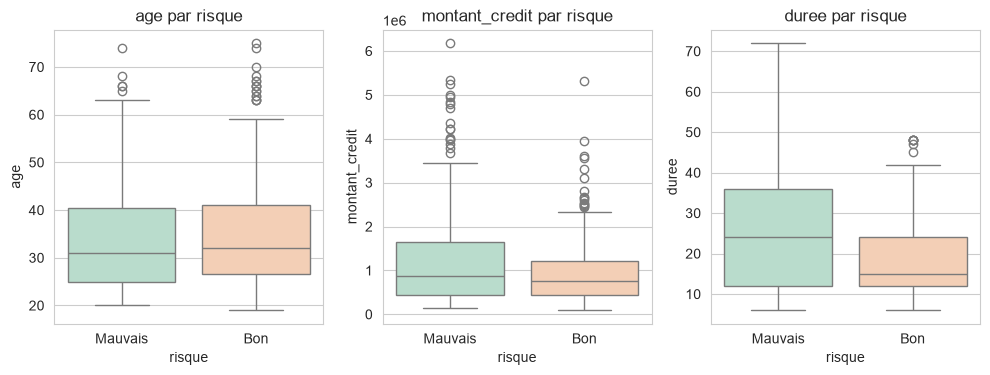

In [187]:
# Diagrammes en boite des caractéristiques numériques séparées par risque
plt.figure(figsize=(10, 4))

for i, col in enumerate(["age", "montant_credit", "duree"]):
    plt.subplot(1, 3, i+1)
    sns.boxplot(data=df, x = 'risque', y = col , hue='risque', palette= 'Pastel2')
    plt.title(f"{col} par risque")

plt.tight_layout()
plt.show()

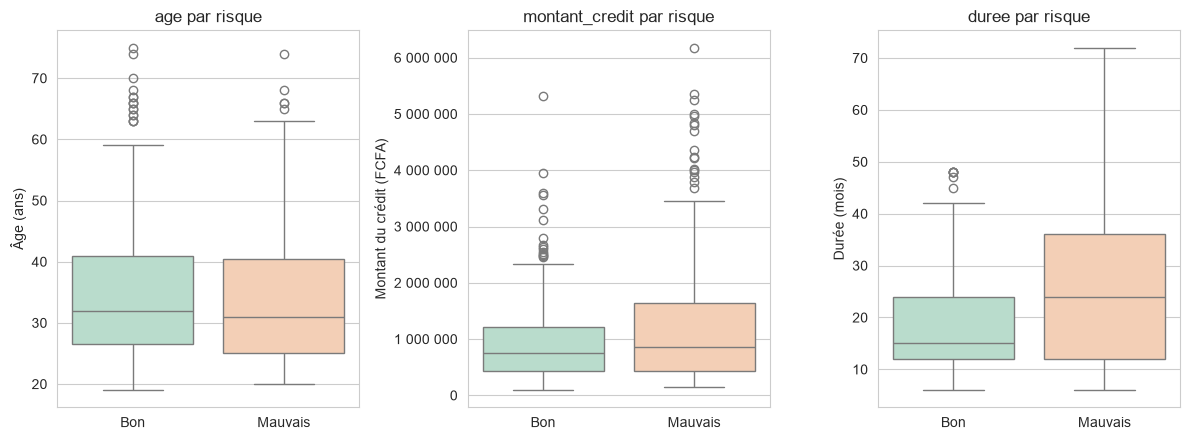

In [188]:
from matplotlib.ticker import FuncFormatter

plt.close("all")
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
ordre = ["Bon", "Mauvais"]

for ax, col in zip(axes, ["age", "montant_credit", "duree"]):
    sns.boxplot(data=df, x="risque", y=col, order=ordre,
                hue="risque", hue_order=ordre, palette="Pastel2",
                legend=False, ax=ax)
    ax.set_title(f"{col} par risque")
    ax.set_xlabel("")

axes[0].set_ylabel("Âge (ans)")
axes[1].set_ylabel("Montant du crédit (FCFA)")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
axes[2].set_ylabel("Durée (mois)")

plt.tight_layout()
plt.show()

#### Interprétation : variables numériques selon le risque

**Durée du crédit : la variable la plus discriminante**
- La médiane est d'environ **24 mois** pour les « Mauvais » contre **15 mois** pour les « Bon ».
- Le dernier quart des « Mauvais » dépasse 36 mois, contre 24 mois pour les « Bon ». Les crédits les plus longs (jusqu'à 72 mois) appartiennent aux « Mauvais ».
- Plus la durée est longue, plus l'exposition au risque est longue : c'est cohérent avec l'intuition métier.

**Montant du crédit : un écart plus modéré**
- La médiane est un peu plus haute pour les « Mauvais » (~870 000 FCFA contre ~780 000), et leur 3e quartile est nettement plus élevé (~1,65 M contre ~1,2 M).
- Les très gros crédits (plus de 3,5 M) sont plus nombreux chez les « Mauvais ».
- Les boîtes se chevauchent largement : le montant seul ne sépare pas les deux groupes.

**Âge : presque aucune différence**
- Les médianes (~31 et ~32 ans) et les boîtes sont quasi identiques. Dans cet échantillon, l'âge seul n'aide pas à distinguer les deux profils.

**Précautions**
- Le montant et la durée sont probablement liés entre eux (un gros crédit est souvent long) : une partie de l'effet du montant peut venir de la durée. À vérifier avec une corrélation de Spearman.
- Les boîtes se chevauchent pour les trois variables : aucune ne suffit seule, un modèle les combinera avec les variables catégorielles.
- Ces constats sont des associations, pas des causes, et portent sur l'échantillon sans valeurs manquantes (la proportion de « Mauvais » y est plus élevée que dans le jeu complet).

**Conclusion**
La durée est la variable numérique la plus informative, le montant l'est moins, et l'âge très peu. Ces premières intuitions seront à confirmer par la modélisation.

In [189]:
# Calculer les moyennes par groupe 
df.groupby("risque")[["age", "montant_credit", "duree"]].mean()

,age,montant_credit,duree
risque,,,
Bon,35.477663,9.392787e+05,18.079038
Mauvais,34.147186,1.301662e+06,25.445887


In [190]:
categorical_cols

['sexe',
 'qualification_emploi',
 'logement',
 'compte_epargne',
 'compte_courant',
 'objet_credit']

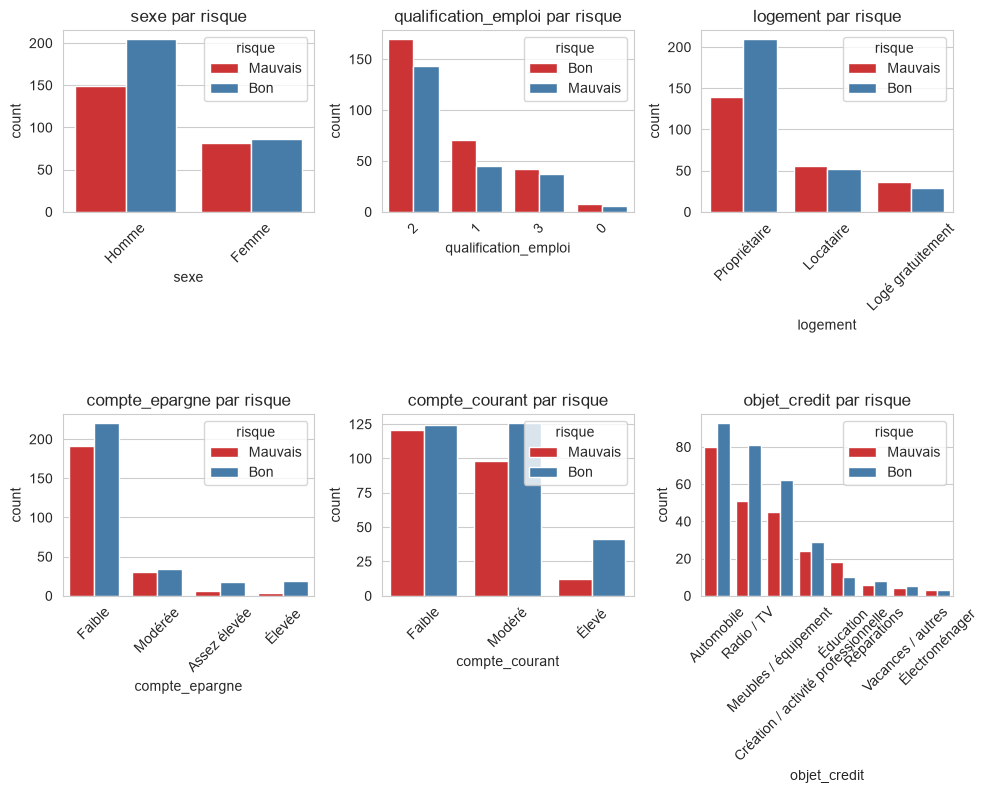

In [191]:
plt.figure(figsize=(10, 10))
for i, col in enumerate(categorical_cols): 
    plt.subplot(3, 3, i+1)
    sns.countplot(data=df, x = col, hue= "risque", palette = "Set1", order=df[col].value_counts().index)
    plt.title(f"{col} par risque")
    plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()


#### Feature engineering 

In [192]:
df.columns

Index(['age', 'sexe', 'qualification_emploi', 'logement', 'compte_epargne',
       'compte_courant', 'montant_credit', 'duree', 'objet_credit', 'risque',
       'montant_credit_dm'],
      dtype='str')

##### Sélection des variables 

In [193]:
features = ["age", "sexe", "qualification_emploi", "logement", "compte_epargne", "compte_courant", "montant_credit", "duree"]

In [194]:
target = "risque"

In [195]:
df_model = df[features + [target]].copy() 

In [196]:
df_model.head()

,age,sexe,qualification_emploi,logement,compte_epargne,compte_courant,montant_credit,duree,risque
0,22,Femme,2,Propriétaire,Faible,Modéré,1995879,48,Mauvais
1,45,Homme,2,Logé gratuitement,Faible,Faible,2643508,42,Bon
2,53,Homme,2,Logé gratuitement,Faible,Faible,1633327,24,Mauvais
3,35,Homme,3,Locataire,Faible,Modéré,2330258,36,Bon
4,28,Homme,3,Propriétaire,Faible,Modéré,1755408,30,Mauvais


Nous allons pas faire de mise à l'échelle (StandardScaler/MinMaxScaler/RobustScaler) vu qu'on va travailler avec des modèles basés sur les arbres.  

##### Encodage des variables catégorielles / Importation des bibliothèques 

In [197]:
from sklearn.preprocessing import LabelEncoder 
import joblib 

**LabelEncoder** attribue les codes dans l'ordre alphabétique : « Bon » vient avant « Mauvais », donc Bon = 0 et Mauvais = 1

In [198]:
# Sélection des variables catégorielles 
cat_cols = df_model.select_dtypes(include = "object").columns.drop('risque')
cat_cols

C:\Users\DELL1\AppData\Local\Temp\ipykernel_25680\231759523.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_model.select_dtypes(include = "object").columns.drop('risque')


Index(['sexe', 'logement', 'compte_epargne', 'compte_courant'], dtype='str')

In [199]:
# Dictionnaire des encodeurs de Labels 
le_dict = {} 

In [200]:
# Encodage de chacune des variables catégorielles et sauvegarde de l'encodeur avec joblib
for col in cat_cols: 
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    le_dict[col] = le 
    joblib.dump(le, f"{col}_encoder.pkl")

In [201]:
le_dict

{'sexe': LabelEncoder(),
 'logement': LabelEncoder(),
 'compte_epargne': LabelEncoder(),
 'compte_courant': LabelEncoder()}

In [202]:
# Encodage de la variable cible 
le_target = LabelEncoder()

In [203]:
target

'risque'

In [204]:
df_model[target] = le_target.fit_transform(df_model[target])

In [205]:
df_model[target] 

0      1
1      0
2      1
3      0
4      1
      ..
517    0
518    0
519    0
520    1
521    0
Name: risque, Length: 522, dtype: int64

In [206]:
df_model[target].value_counts()

risque
0    291
1    231
Name: count, dtype: int64

In [207]:
df['risque'].value_counts() 

risque
Bon        291
Mauvais    231
Name: count, dtype: int64

In [208]:
print(dict(zip(le_target.classes_, le_target.transform(le_target.classes_))))
# {'Bon': 0, 'Mauvais': 1}

{'Bon': np.int64(0), 'Mauvais': np.int64(1)}


In [209]:
joblib.dump(le_target, "target_encoder.pkl") 

['target_encoder.pkl']

In [210]:
df_model.head()

,age,sexe,qualification_emploi,logement,compte_epargne,compte_courant,montant_credit,duree,risque
0,22,0,2,2,1,1,1995879,48,1
1,45,1,2,1,1,0,2643508,42,0
2,53,1,2,1,1,0,1633327,24,1
3,35,1,3,0,1,1,2330258,36,0
4,28,1,3,2,1,1,1755408,30,1


##### Division des variables en ensemble d'entrainement et de test  

In [211]:
from sklearn.model_selection import train_test_split 

In [212]:
X = df_model.drop(target, axis = 1)

In [213]:
y = df_model[target] 

In [214]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [215]:
X_train.shape

(417, 8)

In [216]:
X_test.shape

(105, 8)

#### Modélisation 

In [217]:
#!uv add xgboost
#!uv add scikit-learn

In [ ]:
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
for nom, y_ in [("Train", y_train), ("Test", y_test)]:
    print(f"{nom} - répartition de la cible :", y_.value_counts(normalize=True).round(3).to_dict())

print("\nValeurs manquantes dans X_train :", X_train.isna().sum().sum())
print("\nTypes des colonnes :")
print(X_train.dtypes.value_counts())

In [232]:
# Importation des modèles 
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier 
from sklearn.metrics import (accuracy_score, roc_auc_score, recall_score,
                             precision_score, f1_score, confusion_matrix)
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from scipy.stats import ks_2samp

In [227]:
# Fonction train_model() 
def train_model(model, param_grid, X_train, y_train, X_test, y_test): 
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1", "accuracy": "accuracy"}

    # refit="roc_auc" : la meilleure combinaison est choisie sur l'AUC
    grid = GridSearchCV(model, param_grid, cv=cv, scoring=scoring,
                        refit="roc_auc", n_jobs=-1)
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    y_true = np.asarray(y_test)
    y_pred = best_model.predict(X_test)
    y_proba = best_model.predict_proba(X_test)[:, 1]    # probabilité de défaut

    auc = roc_auc_score(y_true, y_proba)
    resultats = {
        "auc_cv": grid.best_score_,                      # AUC moyenne en validation croisée
        "auc_test": auc,
        "gini": 2 * auc - 1,
        "ks": ks_2samp(y_proba[y_true == 1], y_proba[y_true == 0]).statistic,
        "rappel": recall_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "confusion": confusion_matrix(y_true, y_pred),
    }
    return best_model, resultats, grid.best_params_

In [ ]:
LIBELLES = {
    "auc_cv":    "AUC (validation croisée)",
    "auc_test":  "AUC (test)",
    "gini":      "Gini (test)",
    "ks":        "KS (test)",
    "rappel":    "Rappel - classe Mauvais (test)",
    "precision": "Précision - classe Mauvais (test)",
    "f1":        "F1 (test)",
    "accuracy":  "Accuracy (test)",
}

# Fonction pour afficher les métriques 
def afficher_metriques(nom, resultats, params):
    print(f"=== {nom} ===")
    print("Meilleurs hyperparamètres :", params, "\n")

    tab = pd.DataFrame({LIBELLES[k]: [round(resultats[k], 3)] for k in LIBELLES},
                       index=["Valeur"]).T
    display(tab)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(resultats["confusion"],
                           display_labels=["Bon", "Mauvais"]).plot(
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Matrice de confusion - {nom}")
    plt.tight_layout()
    plt.show()

##### DecisionTreeClassifier


In [228]:
dt = DecisionTreeClassifier(random_state=1, class_weight="balanced")
dt_param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [229]:
best_dt, results_dt, params_dt = train_model(dt, dt_param_grid, X_train, y_train, X_test, y_test)

In [ ]:
LIBELLES = {
    "auc_cv":    "AUC (validation croisée)",
    "auc_test":  "AUC (test)",
    "gini":      "Gini (test)",
    "ks":        "KS (test)",
    "rappel":    "Rappel - classe Mauvais (test)",
    "precision": "Précision - classe Mauvais (test)",
    "f1":        "F1 (test)",
    "accuracy":  "Accuracy (test)",
}

def afficher_metriques(nom, resultats, params):
    print(f"=== {nom} ===")
    print("Meilleurs hyperparamètres :", params, "\n")

    tab = pd.DataFrame({LIBELLES[k]: [round(resultats[k], 3)] for k in LIBELLES},
                       index=["Valeur"]).T
    display(tab)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(resultats["confusion"],
                           display_labels=["Bon", "Mauvais"]).plot(
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Matrice de confusion - {nom}")
    plt.tight_layout()
    plt.show()

=== Arbre de décision ===
Meilleurs hyperparamètres : {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10} 



,Valeur
AUC (validation croisée),0.628
AUC (test),0.673
Gini (test),0.346
KS (test),0.385
Rappel - classe Mauvais (test),0.543
Précision - classe Mauvais (test),0.610
F1 (test),0.575
Accuracy (test),0.648


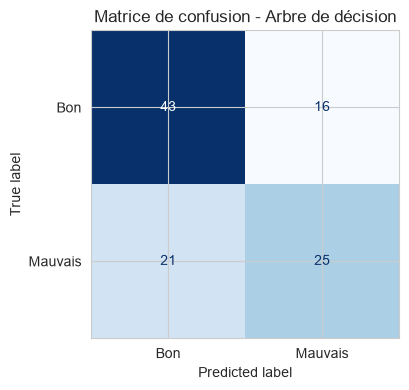

In [231]:
afficher_metriques("Arbre de décision", results_dt, params_dt)